In [22]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor
import numpy as np
import torch.optim as optim
import matplotlib as mpb
from matplotlib import pyplot as plt
from sklearn import metrics
import seaborn as sn
import pandas as pd

In [23]:
dataset = np.load("EBRNTrainBig07.npy")
print(dataset.shape)
datatr = dataset[0:8000,:]
print(datatr.shape)
datatst = dataset[8000:10000,:]
print(datatst.shape)
x = dataset[:,0:50]
y = dataset[:,50]
xtr = x[0:8000,:]
xtest = x[8000:10000,:]
# x = torch.tensor(x, dtype=torch.float32)
print(x.shape)
print(xtr.shape)
print(xtest.shape)
y = torch.tensor(y, dtype=torch.float32).reshape(-1)
y = y.long()
print(y.shape)
print(xtr)
print(y)

(10000, 51)
(8000, 51)
(2000, 51)
(10000, 50)
(8000, 50)
(2000, 50)
torch.Size([10000])
[[ 1.78460799e-03 -1.61057600e-03  5.64765613e-04 ... -3.85205053e-04
  -7.55759309e-04 -1.20565686e-04]
 [-5.15953016e-04  5.29608503e-04  7.76667332e-04 ...  6.62993580e-04
   1.78522461e-03  3.49493214e-04]
 [-2.16979956e-04 -1.87707114e-04 -4.48794007e-04 ...  9.66644932e-06
  -1.87302967e-03  6.91801144e-05]
 ...
 [ 3.96165871e-04  9.76218377e-04  1.06253522e-04 ...  6.28690511e-04
  -1.00052113e-03 -1.06341582e-04]
 [ 9.23235540e-04  8.91520108e-04 -6.97240260e-05 ... -3.49944294e-05
   3.56719940e-04 -8.52195153e-04]
 [-1.68019986e-03  2.42214417e-04 -9.95557400e-04 ...  7.84898716e-04
   4.32324073e-04 -6.44756954e-04]]
tensor([6, 6, 6,  ..., 2, 2, 2])


In [29]:
batch_size = 200

class EDEN(nn.Module):
    def __init__(self):
        super().__init__()

        self.strided = nn.Sequential(
            nn.Conv1d(batch_size,batch_size,3,padding='same'),
            nn.BatchNorm1d(50),
            nn.LeakyReLU()
        )

        self.res1 = nn.Sequential(
            nn.Conv1d(batch_size,batch_size,3,padding='same'),
            # nn.BatchNorm1d(50),
            nn.LeakyReLU(),
            nn.Conv1d(batch_size,batch_size,3,padding='same'),
            # nn.BatchNorm1d(50),
            nn.LeakyReLU(),
            # nn.MaxPool1d(1,dilation=2),
            nn.Dropout(0.02)
        )
        self.res2 = nn.Sequential(
            nn.Conv1d(batch_size,batch_size,3,padding='same'),
            # nn.BatchNorm1d(50),
            nn.LeakyReLU(),
            nn.Conv1d(batch_size,batch_size,3,padding='same'),
            # nn.BatchNorm1d(50),
            nn.LeakyReLU(),
            # nn.MaxPool1d(1,dilation=2),
            nn.Dropout(0.02)
        )

        self.res3 = nn.Sequential(
            nn.Conv1d(batch_size,batch_size*2,3,padding='same'),
            # nn.BatchNorm1d(50),
            nn.LeakyReLU(),
            nn.Conv1d(batch_size*2,batch_size*2,3,padding='same'),
            # nn.BatchNorm1d(50),
            nn.LeakyReLU(),
            nn.Dropout(0.02)
        )

        self.res4 = nn.Sequential(
            nn.Conv1d(batch_size*2,batch_size*2,3,padding='same'),
            # nn.BatchNorm1d(50),
            nn.LeakyReLU(),
            nn.Conv1d(batch_size*2,batch_size,3,padding='same'),
            # nn.BatchNorm1d(50),
            nn.LeakyReLU(),
            # nn.MaxPool1d(1,dilation=2),
            nn.Dropout(0.04)
        )

        self.gru = nn.GRU(50,200,batch_first=True)
        
        self.speaker = nn.Sequential(
            nn.Linear(200,100),
            nn.ReLU(),
            nn.Linear(100,8),
            nn.Sigmoid()
        )
        
    def forward(self,x):
        print(x.shape)
        x = self.strided(x)
        print(x.shape)
        res = x
        x = self.res1(x) + res
        res = x
        x = self.res2(x) + res
        print(x.shape)
        res = x
        x = self.res3(x)
        x = self.res4(x) + res
        print(x.shape)
        x = self.gru(x)
        # x = torch.tensor(x, dtype=torch.float32)
        x = x[0]
        print(x.shape)
        x = self.speaker(x)
        print(len(x))
        return x

model = EDEN()
print(model)

EDEN(
  (strided): Sequential(
    (0): Conv1d(200, 200, kernel_size=(3,), stride=(1,), padding=same)
    (1): BatchNorm1d(50, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.01)
  )
  (res1): Sequential(
    (0): Conv1d(200, 200, kernel_size=(3,), stride=(1,), padding=same)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Conv1d(200, 200, kernel_size=(3,), stride=(1,), padding=same)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Dropout(p=0.02, inplace=False)
  )
  (res2): Sequential(
    (0): Conv1d(200, 200, kernel_size=(3,), stride=(1,), padding=same)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Conv1d(200, 200, kernel_size=(3,), stride=(1,), padding=same)
    (3): LeakyReLU(negative_slope=0.01)
    (4): Dropout(p=0.02, inplace=False)
  )
  (res3): Sequential(
    (0): Conv1d(200, 400, kernel_size=(3,), stride=(1,), padding=same)
    (1): LeakyReLU(negative_slope=0.01)
    (2): Conv1d(400, 400, kernel_size=(3,), stride=(1,),

In [30]:
los_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

torch.Size([8000, 50])
torch.Size([8000])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 200])
200
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 200])
200
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 200])
200
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 200])
200
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 200])
200
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 200])
200
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 200])
200
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 200])
200
torch.Size([200, 50])
torch.Size([200,

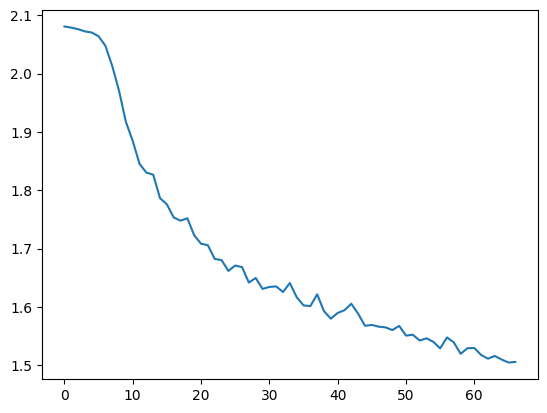

In [31]:
epochlist = []
traininglist = []

n_epochs = 67

dataslice = datatr
xslice = dataslice[:,0:50]
yslice = dataslice[:,50]
xslice = torch.tensor(xslice, dtype = torch.float32)
print(xslice.shape)
yslice = torch.tensor(yslice, dtype = torch.long)
print(yslice.shape)

for j in range(0,5):
    datadrop = datatr[(j*160):(((j+1)*160)),:]
    dataslice = datatr
    sliceindices = []
    for k in range(160):
        if (dataslice[((j*160)+k),:] == datadrop[k,:]).all():
            sliceindices.append(k)
            
    for l in range(len(sliceindices)):
        dataslice = np.delete(dataslice, l, axis=0)
        for m in range(len(sliceindices)):
            sliceindices[m] -= 1

    np.random.shuffle(dataslice)
        
for epoch in range(n_epochs):
    for i in range(0, len(xslice), batch_size):
        xbatch = xslice[i:i+batch_size]
        # xbatch = xbatch.transpose(-2,-1)
        ypred = model(xbatch)
        ybatch = yslice[i:i+batch_size]
        loss = los_fn(ypred, ybatch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    epochlist.append(epoch)
    traininglist.append(loss.item())
    print(f"Finished epoch {epoch}, latest loss {loss}")
plt.plot(epochlist,traininglist)
plt.ylabel = "Loss"
plt.xlabel = "Epochs"
plt.savefig("lossepochs")
plt.show()

torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 200])
200
probs tensor([[0.0837, 0.0837, 0.2274,  ..., 0.2274, 0.1269, 0.0837],
        [0.2375, 0.0874, 0.0874,  ..., 0.0874, 0.0874, 0.2376],
        [0.1013, 0.1013, 0.1092,  ..., 0.1109, 0.1013, 0.1013],
        ...,
        [0.0865, 0.0865, 0.2056,  ..., 0.1933, 0.0865, 0.0865],
        [0.1317, 0.0926, 0.0926,  ..., 0.0926, 0.0926, 0.1733],
        [0.0767, 0.0768, 0.2084,  ..., 0.2084, 0.1996, 0.0767]])
winners tensor([5, 7, 4, 4, 4, 4, 4, 2, 4, 2, 2, 4, 4, 4, 0, 0, 4, 2, 4, 4, 2, 2, 2, 2,
        4, 4, 4, 0, 2, 4, 7, 4, 2, 4, 2, 0, 2, 0, 4, 2, 2, 2, 4, 2, 0, 2, 2, 7,
        4, 0, 0, 2, 4, 2, 2, 2, 4, 4, 2, 4, 4, 2, 4, 2, 2, 4, 2, 7, 7, 4, 2, 2,
        0, 2, 7, 2, 4, 7, 2, 4, 4, 2, 4, 0, 4, 4, 2, 4, 2, 2, 7, 4, 4, 0, 2, 2,
        2, 4, 2, 2, 0, 4, 5, 4, 2, 0, 7, 4, 2, 2, 2, 4, 2, 2, 4, 2, 4, 0, 2, 2,
        5, 7, 2, 4, 2, 0, 7, 2, 2, 2, 4, 2, 4, 2, 2, 2, 5, 4, 2, 2, 2, 4,

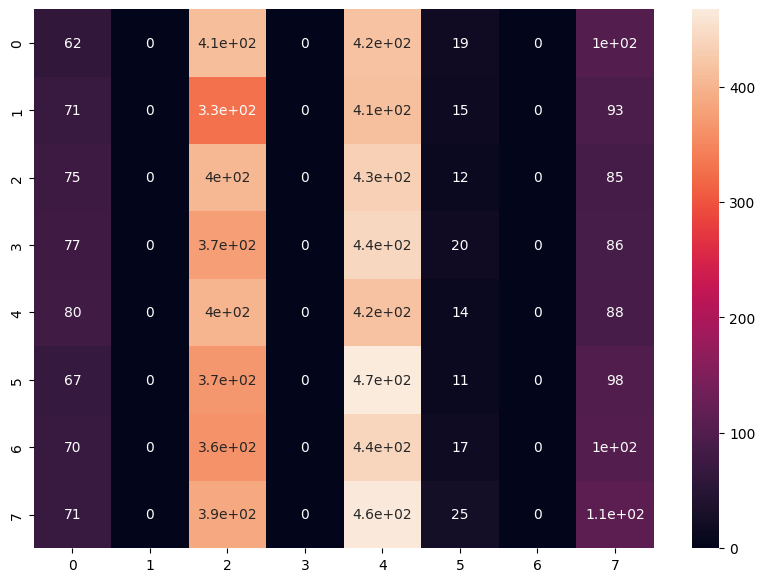

In [32]:
accuracylist = np.array([])
winnerslist = np.array([])
actuallist = np.array([])

dataacc = datatr
np.random.shuffle(dataacc)
xacc = dataacc[:,:50]
yacc = dataacc[:,50]
xacc = torch.tensor(xacc, dtype=torch.float32)
yacc = torch.tensor(yacc, dtype=torch.long)

with torch.no_grad():
    for i in range(0, len(xacc), batch_size):
        xbatch = xacc[i:i+batch_size]
        # xbatch = xbatch.transpose(-2,-1)
        ypred = model(xbatch)
        ybatch = yacc[i:i+batch_size]
        probs = torch.softmax(ypred, dim=1)
        print("probs "+ str(probs))
        winners = probs.argmax(dim=1)
        print("winners "+ str(winners))
        print("actual "+str(ybatch))
        winnerslist = np.append(winnerslist, winners)
        actuallist = np.append(actuallist, ybatch)

print("winning hand "+str(winnerslist))
for i in range(len(winnerslist)):
    winnerslist[i] = int(winnerslist[i])
    actuallist[i] = int(actuallist[i])

for i in range(len(winnerslist)):
    if winnerslist[i] == actuallist[i]:
        accuracy = 1
    else:
        accuracy = 0
    accuracylist = np.append(accuracylist, accuracy)

print(actuallist)

accfinal = sum(accuracylist)/len(accuracylist)
print(f"Accuracy {accfinal}")

# print(winnerslist)
# print(f"Accuracy list {accuracylist}")

confarray = [[0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0]]

for i in range(len(actuallist)):
    position1 = int(actuallist[i])
    position2 = int(winnerslist[i])
    confarray[position1][position2] += 1

df_cm = pd.DataFrame(confarray, index = [i for i in "01234567"],
                  columns = [i for i in "01234567"])
plt.figure(figsize = (10,7))
ax = sn.heatmap(df_cm, annot=True)
plt.savefig("edenCM.png")

/tmp/ipykernel_2961186/1648941867.py:5: UserWarning: you are shuffling a 'Tensor' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  np.random.shuffle(xtest)
/tmp/ipykernel_2961186/1648941867.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  xtest = torch.tensor(xtest, dtype=torch.float32)


torch.Size([2000, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 50])
torch.Size([200, 200])
200
probs tensor([[0.0848, 0.0848, 0.2304,  ..., 0.2304, 0.1152, 0.0848],
        [0.0870, 0.0870, 0.2345,  ..., 0.2340, 0.0871, 0.0870],
        [0.1021, 0.1021, 0.1063,  ..., 0.1073, 0.1021, 0.1021],
        ...,
        [0.0873, 0.0873, 0.2373,  ..., 0.2372, 0.0889, 0.0873],
        [0.1106, 0.0996, 0.0996,  ..., 0.0996, 0.0996, 0.1272],
        [0.2376, 0.0874, 0.0874,  ..., 0.0874, 0.0874, 0.2376]])
winners tensor([5, 2, 4, 2, 2, 2, 4, 0, 4, 2, 4, 4, 2, 2, 2, 0, 7, 4, 4, 2, 2, 2, 2, 5,
        4, 2, 2, 4, 2, 4, 4, 4, 2, 2, 7, 0, 2, 4, 7, 2, 2, 4, 4, 2, 4, 2, 4, 4,
        4, 4, 2, 4, 4, 4, 4, 4, 4, 4, 7, 7, 4, 0, 4, 2, 2, 4, 4, 2, 4, 2, 2, 4,
        4, 4, 7, 4, 2, 2, 4, 4, 4, 4, 4, 4, 4, 2, 2, 2, 2, 0, 2, 4, 4, 2, 4, 2,
        4, 4, 2, 2, 4, 4, 4, 2, 4, 2, 4, 7, 2, 4, 2, 2, 2, 2, 4, 2, 4, 4, 0, 7,
        4, 2, 2, 2, 2, 7, 2, 0, 4, 4, 2, 2, 2, 4, 

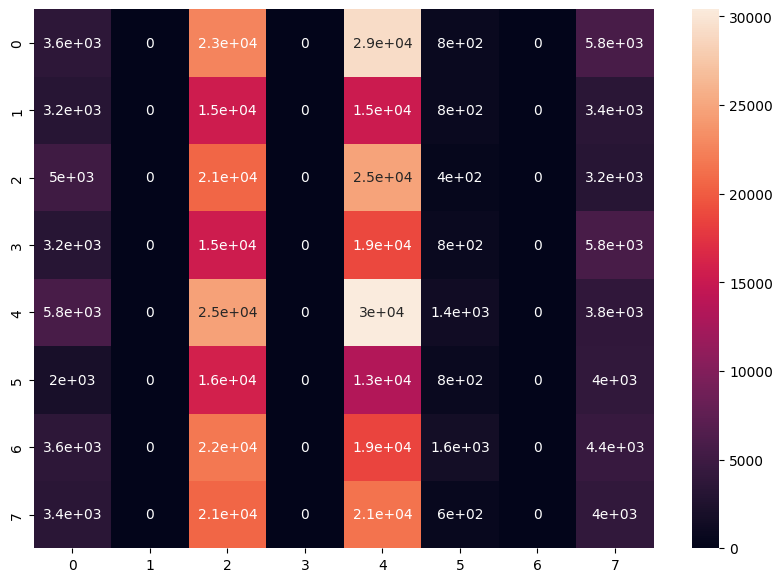

In [33]:
accuracylist = np.array([])
winnerslist = np.array([])
actuallist = np.array([])

np.random.shuffle(xtest)
xtest = torch.tensor(xtest, dtype=torch.float32)
print(xtest.shape)

with torch.no_grad():
    for i in range(0, len(xtest), batch_size):
        xbatch = xtest[i:i+batch_size]
        # xbatch = xbatch.transpose(-2,-1)
        ypred = model(xbatch)
        ybatch = y[i:i+batch_size]
        probs = torch.softmax(ypred, dim=1)
        print("probs "+ str(probs))
        winners = probs.argmax(dim=1)
        print("winners "+ str(winners))
        print("actual "+str(ybatch))
        for i in winners:
            winnerslist = np.append(winnerslist, winners)
        for i in ybatch:
            actuallist = np.append(actuallist, ybatch)
        accuracy = (winners == ybatch).float().mean()
        accuracylist = np.append(accuracylist, accuracy)

print(actuallist)

accfinal = sum(accuracylist)/len(accuracylist)
print(f"Accuracy {accfinal}")

print(winnerslist)
print(f"Accuracy list {accuracylist}")

confarray = [[0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0]]

for i in range(len(actuallist)):
    position1 = int(actuallist[i])
    position2 = int(winnerslist[i])
    confarray[position1][position2] += 1

df_cm = pd.DataFrame(confarray, index = [i for i in "01234567"],
                  columns = [i for i in "01234567"])
plt.figure(figsize = (10,7))
ax = sn.heatmap(df_cm, annot=True)
plt.xlabel = "Predicted"
plt.ylabel = "Actual"
plt.savefig("edenCM.png")